# BVOC – SOA – cloud interactions

Emissions → SOA → aerosol number → cloud droplets, as maps north of 45°N. Plotting code: `boreal_forest_expansion.plotting.forcing_maps`
(`CONTEXT_PANELS`: SFISOP, SFMTERP, SOA burden, N_AER (lowest level), FCTL, in-cloud ACTREL/ACTNL, LWP, ET).

**Data and caveats (read before interpreting)**
- Input: monthly postprocessed files `data/processed-data/postprocessing/[alias]_[atm|lnd]_[CATEGORY]_2001-2009.nc` (first 12 months dropped as spin-up).
  Runs: CTRL `…nudg_ctrl_…-20260925`, LCC `…nudg_lcc_…-20261005`, fBVOC = the ISOP+MTERP-only runs `-20261008` (PD) / `-20261009` (FUT).
- **Provisional:** CTRL `-20260925` is superseded by `-20261023`; everything here is redone on the 2001–2014 set.
- CTRL and LCC have different land spin-ups (LCC: extra 100-yr land-only BGC spin-up) → LCC − CTRL contains a spin-up offset (large in FUT).
- `LCC_FUT − CTRL_PD` = LCC **plus** the whole 2100 background change (SST, GHG, CO₂, emissions): dominated by climate change.
- `LCC_FUT − LCC_FUT_fBVOC`: fBVOC_FUT uses CTRL_PD emissions → mixes the climate-driven emission change with the LCC effect; **not** a forest-expansion-only BVOC effect.
- fBVOC runs lack all non-ISOP/MTERP MEGAN compounds (no `MEG_*`), so LCC − fBVOC is not ISOP+MTERP only.
- Maps: mean of the 9 paired yearly differences. **Grey `/////` hatching = NOT significant** (paired t-test, Benjamini–Hochberg FDR α = 0.10 over the drawn cells ≥45°N).
  Text under each panel: area-weighted mean ≥45°N ± 95 % t-interval across years (land-only fields: land mean).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # repo src/, no pip install needed

import matplotlib.pyplot as plt
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

set_default_style()
START_YEAR, END_YEAR = 2001, 2009
common = dict(start_year=START_YEAR, end_year=END_YEAR, extent_lat=45, mean_lat_min=45, save=True)
print("Figures ->", fm.FIGURE_DIR)
print(fm.BVOC_PAIRS)

Figures -> /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures
{'PD': {'lcc': 'LCC_PD', 'fbvoc': 'LCC_PD_fBVOC', 'ctrl': 'CTRL_PD'}, 'FUT': {'lcc': 'LCC_FUT', 'fbvoc': 'LCC_FUT_fBVOC', 'ctrl': 'CTRL_FUT'}}


## 1. Context maps, LCC − LCC_fBVOC (one figure per period)
Moved unchanged from the old `forcing_maps.ipynb`.

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/PD_bvoc_context_maps_2001_2009.png


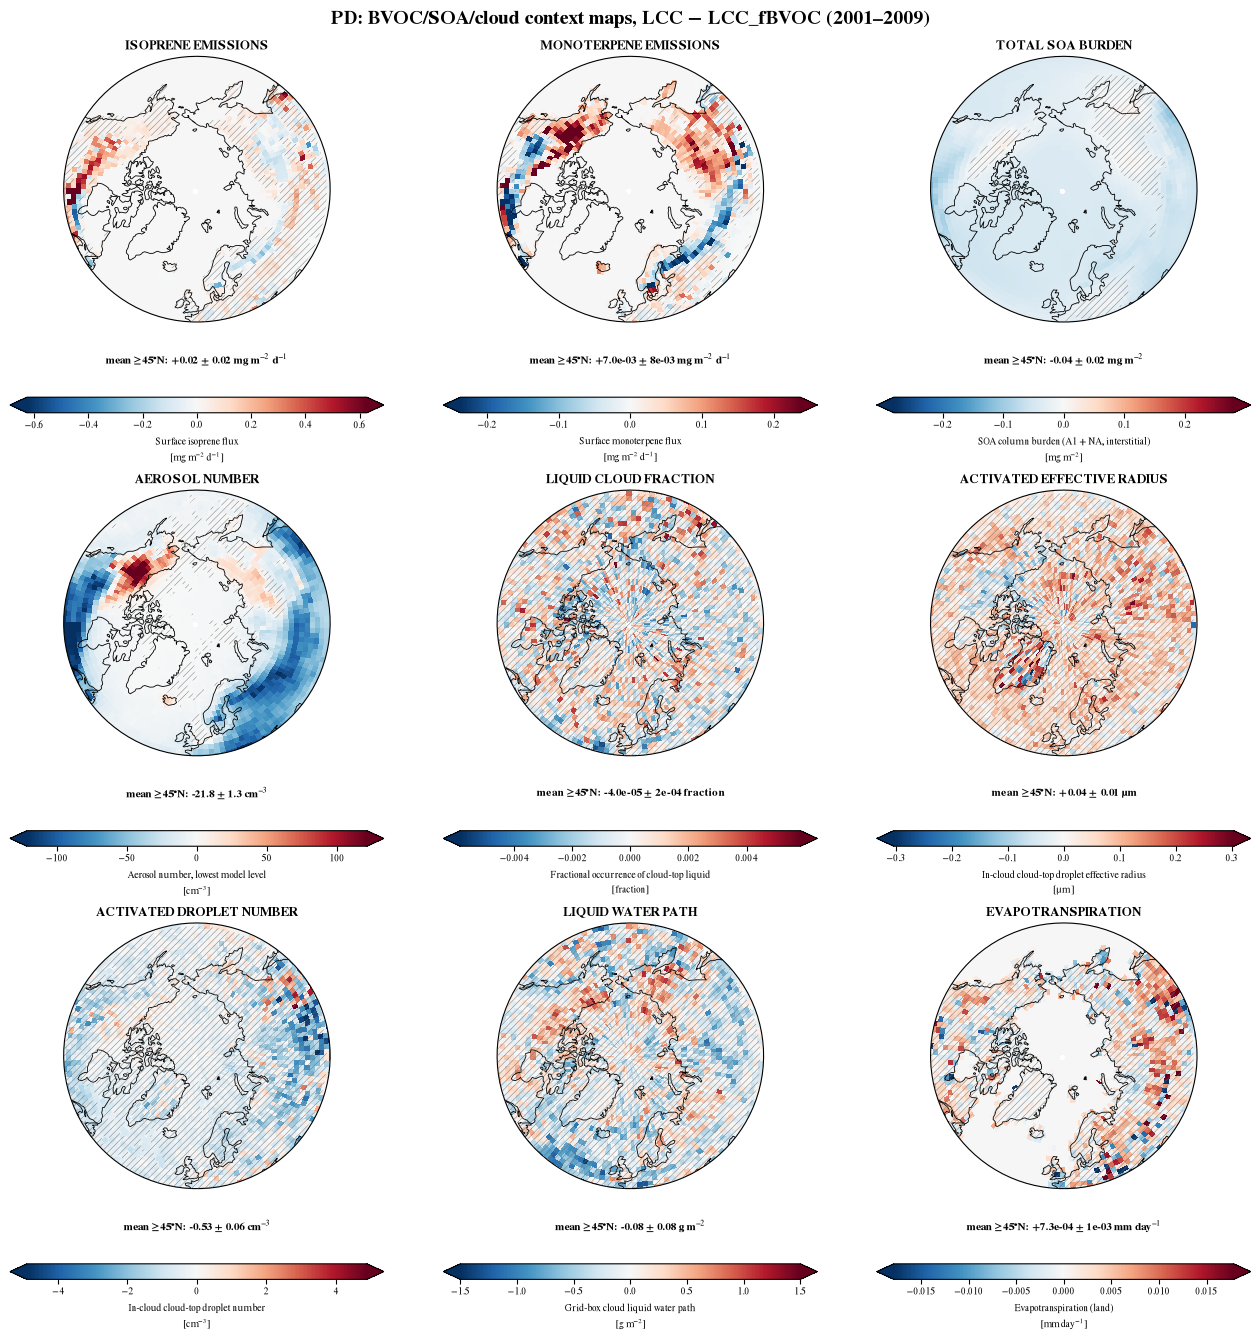

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/FUT_bvoc_context_maps_2001_2009.png


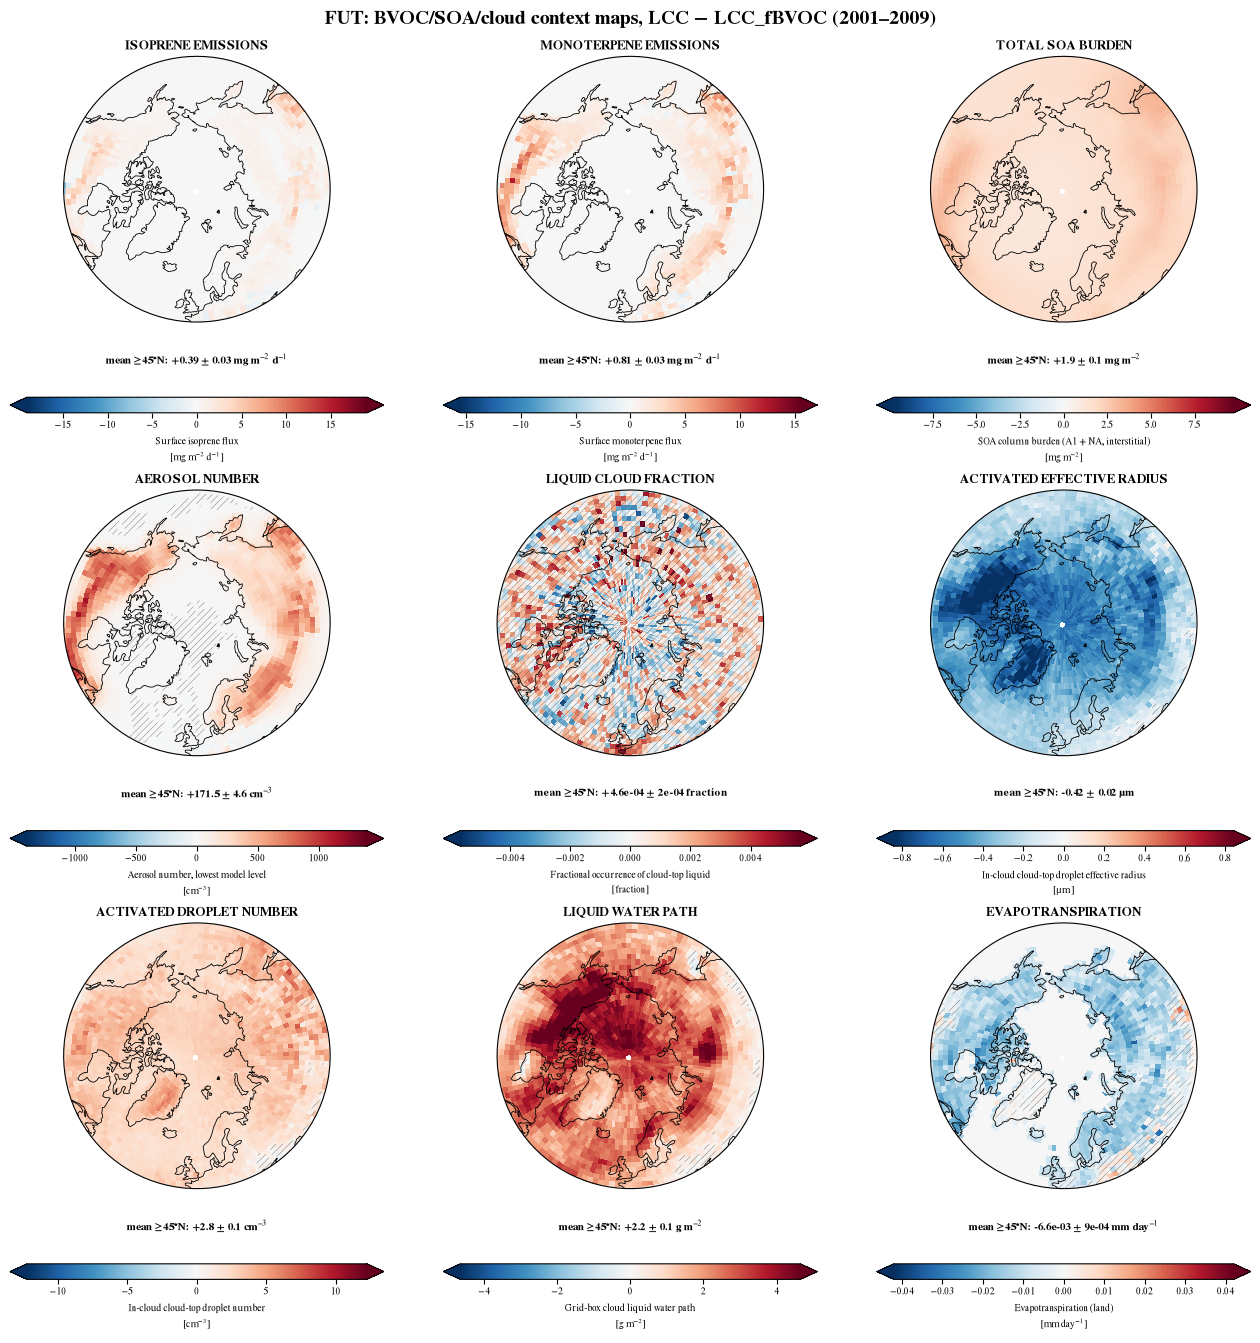

In [2]:
for exp in ("PD", "FUT"):
    fig, axes = fm.make_context_maps_figure(exp, **common)
    plt.show(); plt.close(fig)

## 2. Contrast grids: rows = contrasts, columns = variables
- **LCC-CTRL**: LCC_PD − CTRL_PD, LCC_FUT − CTRL_FUT, LCC_FUT − CTRL_PD.
- **LCC-fBVOC**: LCC_PD − LCC_PD_fBVOC, LCC_FUT − LCC_FUT_fBVOC.
- **fBVOC-CTRL**: LCC_PD_fBVOC − CTRL_PD, LCC_FUT_fBVOC − CTRL_FUT (land-cover change with ISOP/MTERP held at the CTRL_PD climatology and no other MEGAN compounds; LCC−CTRL = fBVOC−CTRL + LCC−fBVOC).

Every panel has its own colour bar: the rows differ by orders of magnitude (LCC_FUT − CTRL_PD contains the full 2100 background).

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_context_LCC-CTRL_2001_2009.png


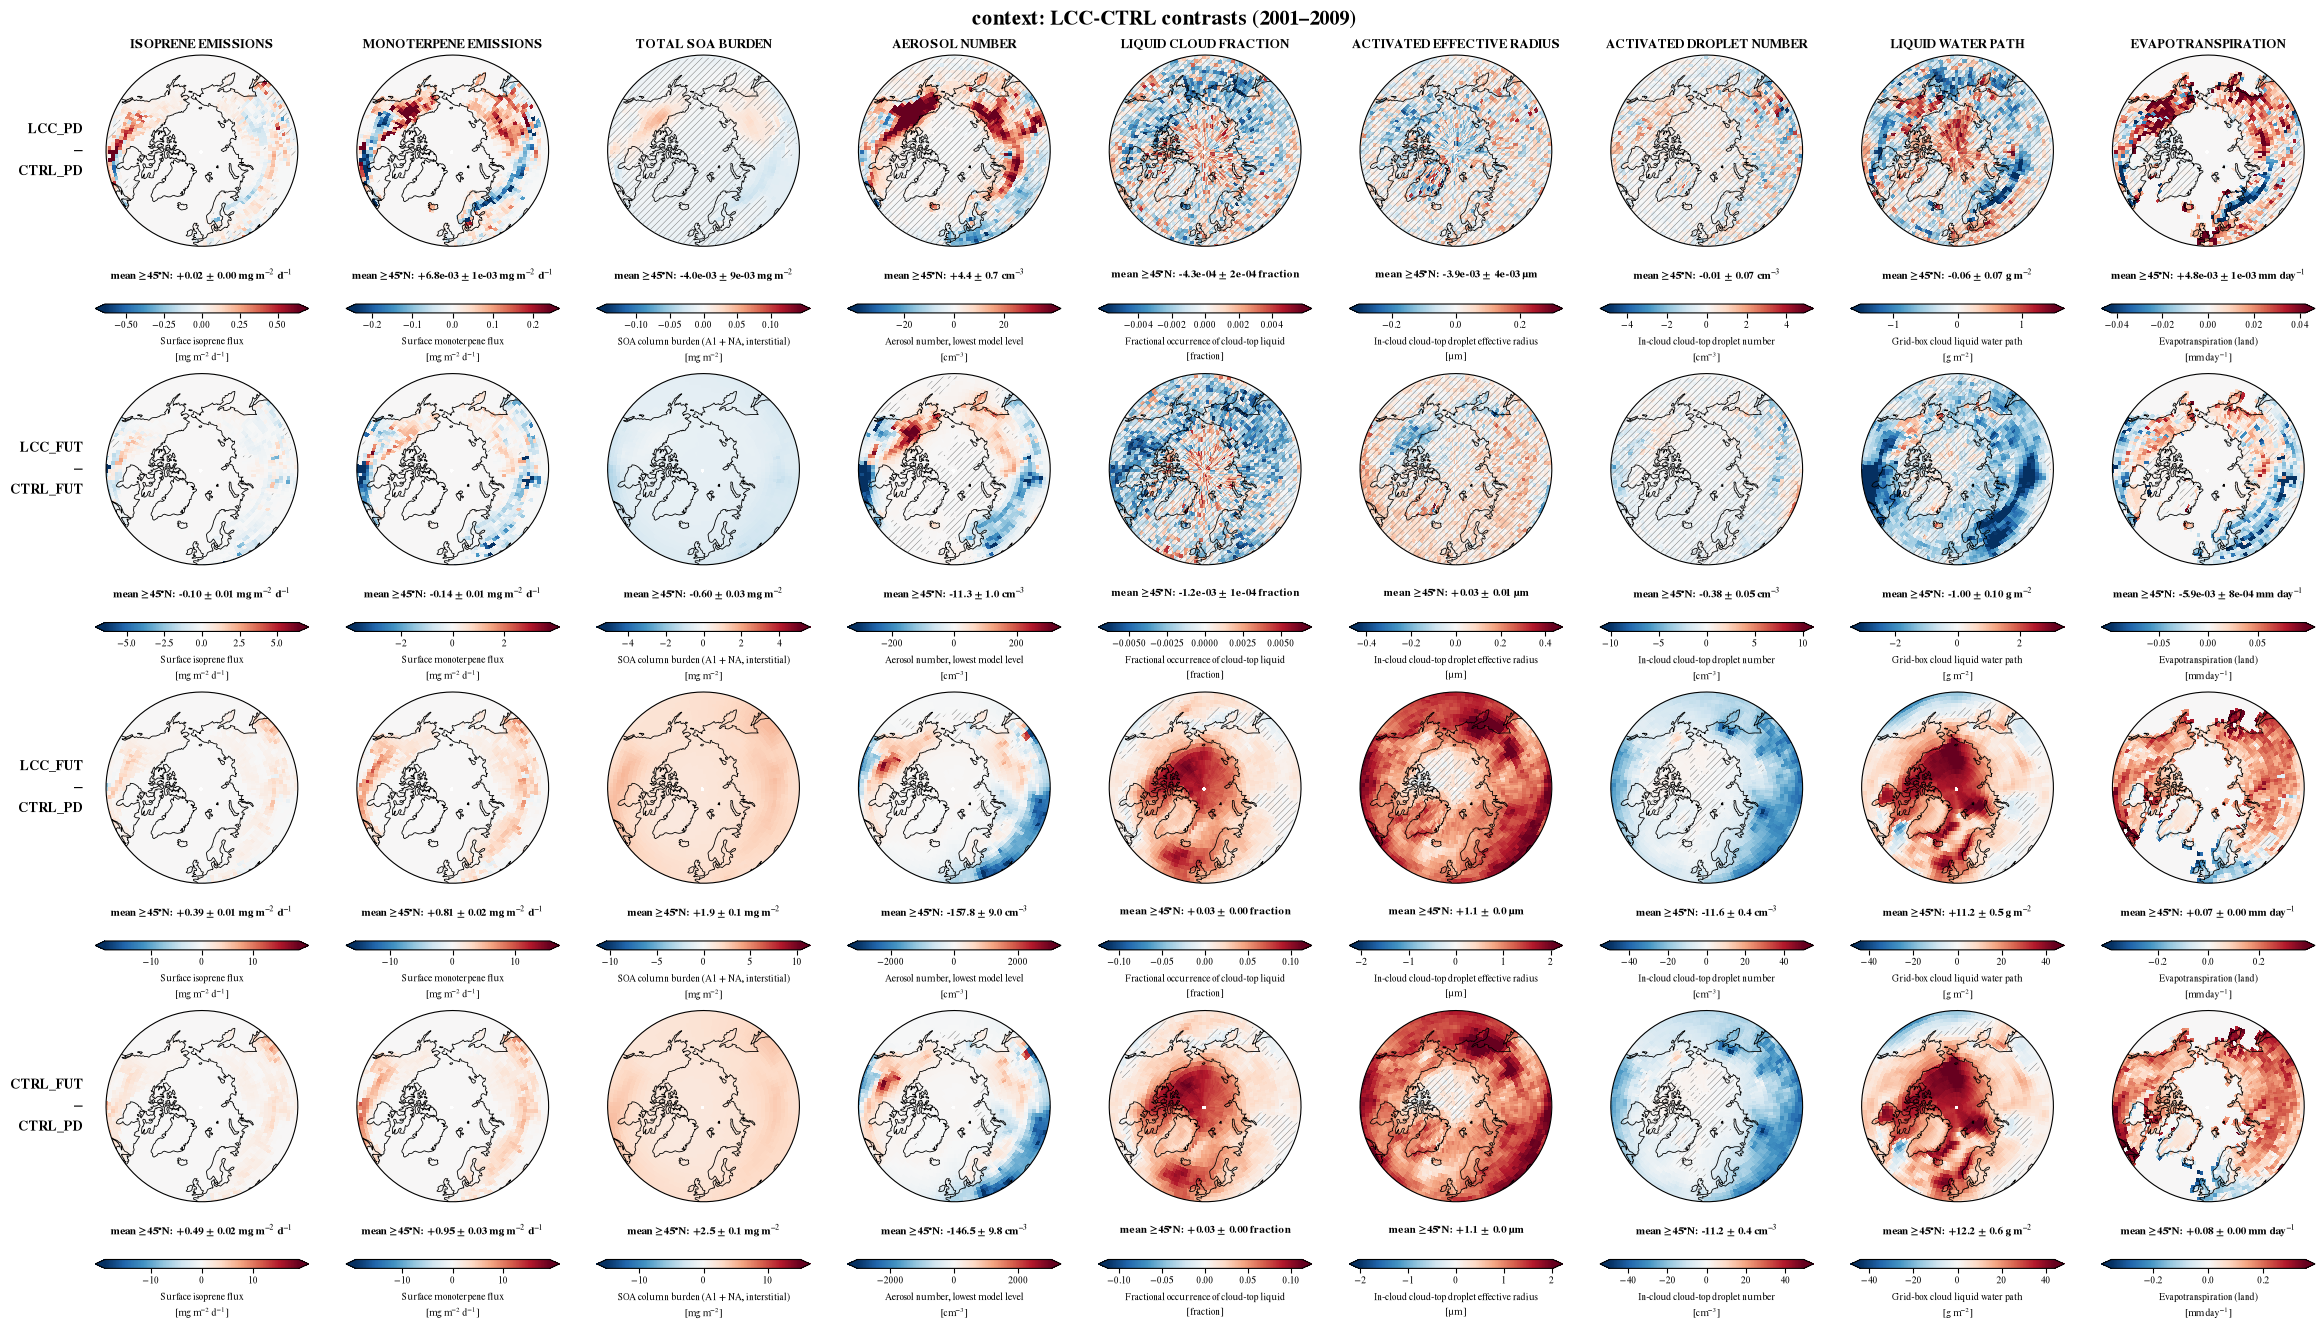

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_context_LCC-fBVOC_2001_2009.png


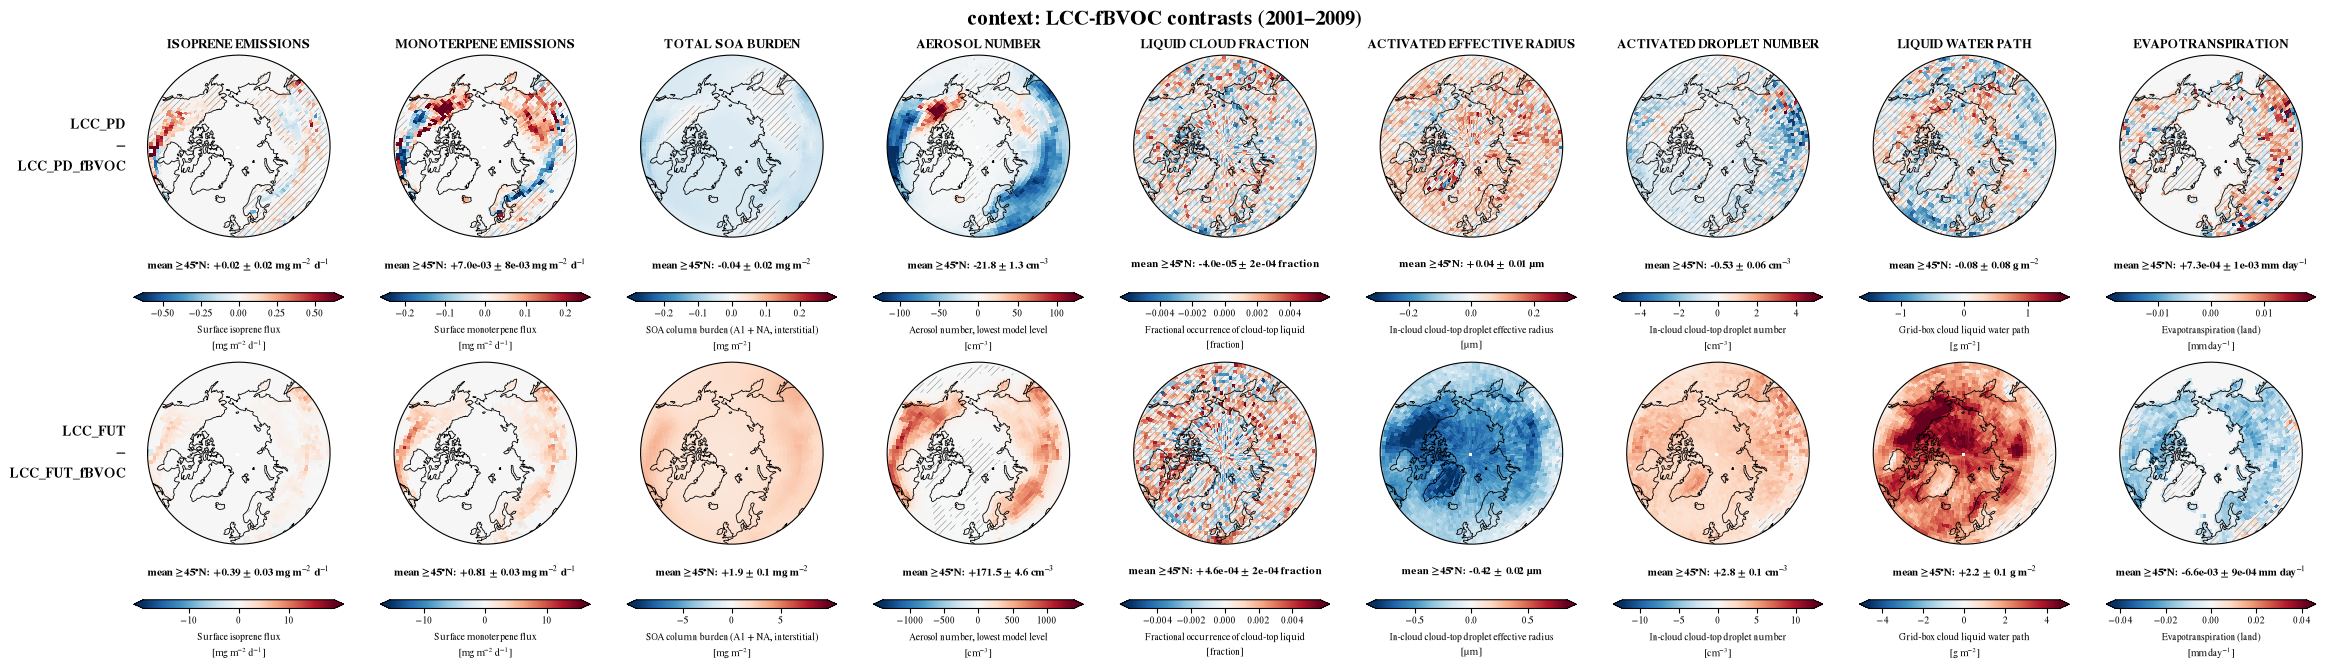

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/contrast_grid_context_fBVOC-CTRL_2001_2009.png


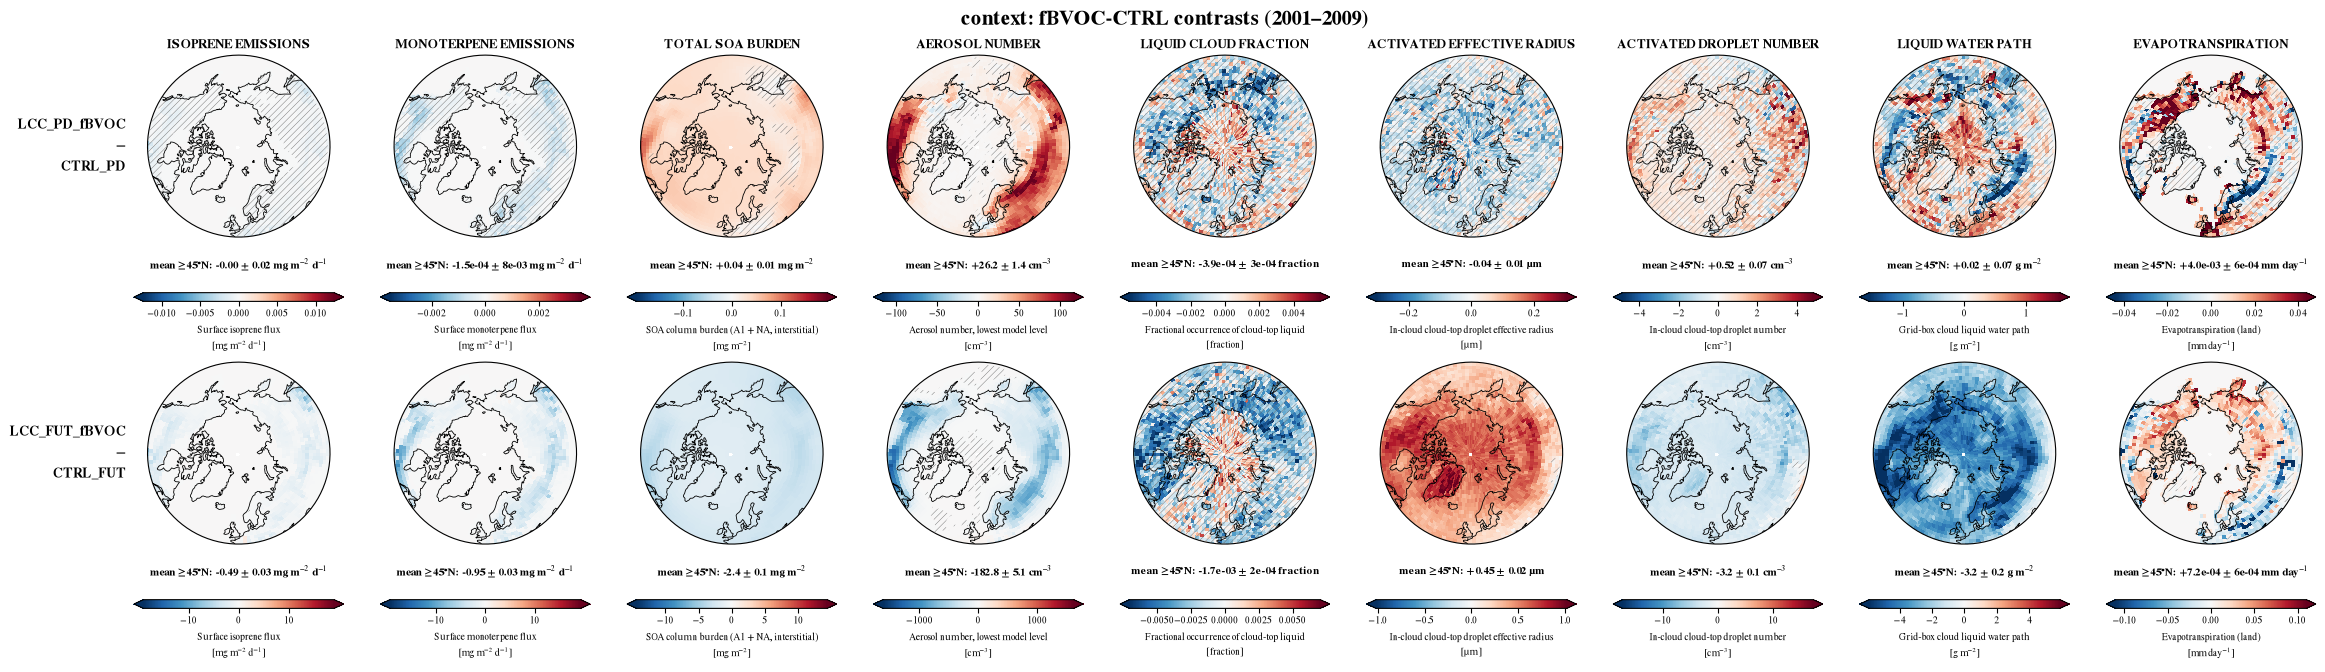

In [3]:
for cset in fm.contrast_sets():
    fig, axes = fm.make_contrast_grid_figure(cset, fm.CONTEXT_PANELS, "context", start_year=START_YEAR, end_year=END_YEAR)
    plt.show(); plt.close(fig)